# Visualizador — Ciclo Hamiltoniano

Proyecto · Lógica para Ciencias de la Computación · Universidad del Rosario
Moises Bulla Ospina · Julian David Parra Granados · Valentina Mesa Fajardo

---

# Generación de las reglas: fórmulas y lenguaje natural

**Problema.** Ciclo hamiltoniano sobre un grafo de ciudades conectadas por carreteras: un recorrido que visita **cada ciudad exactamente una vez** y regresa a la ciudad de origen.

**Descriptor único.** $Visita(c,t)$ = «la ciudad $c$ se visita en la posición $t$», con $c$ y $t$ entre $0$ y $n-1$ ($n$ ciudades, $n$ posiciones). Cada letra proposicional es un carácter de Unicode construido con `Descriptor`, de modo que el número de letras es $n\times n$.

Este notebook muestra, para cada una de las 5 reglas, cómo se genera la fórmula: la regla en lenguaje natural, su forma matemática, el código de `problema.py` que la construye con Y-torias y O-torias, y la fórmula resultante leída en español con el método `ver` de la librería.

El dibujo del grafo, de cada regla y del recorrido vive en `visualizador.py`. Al final de este notebook se **verifican** las reglas con recorridos armados a mano y se dibuja una solución **turno por turno**; en los siguientes notebooks (`02` a `05`) un SAT-solver la encuentra por sí solo.

In [1]:
import sys, inspect
import pandas as pd
import matplotlib.pyplot as plt
from logica import *
from problema import CicloHamiltoniano

sys.setrecursionlimit(10000)   # las reglas son fórmulas largas (recursión profunda)

ciudades = ['Baq', 'Buc', 'Bog', 'Med', 'Per']
aristas  = [{0,1}, {1,2}, {2,3}, {3,4}, {2,4}, {0,2}, {1,4}]
coords   = {0:(0,3), 1:(3,3), 2:(1.5,1.8), 3:(0.3,0), 4:(2.7,0)}   # solo para dibujar

H = CicloHamiltoniano(ciudades, aristas, coords)
print('Ciudades:', H.n, '| posiciones:', H.n, '| letras proposicionales:', H.n * H.n)

Ciudades: 5 | posiciones: 5 | letras proposicionales: 25


## El grafo

Las reglas 4 y 5 dependen de qué ciudades están conectadas, así que mostramos primero el grafo.

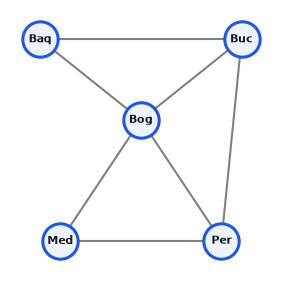

Baq está conectada con: ['Buc', 'Bog']
Buc está conectada con: ['Baq', 'Bog', 'Per']
Bog está conectada con: ['Baq', 'Buc', 'Med', 'Per']
Med está conectada con: ['Bog', 'Per']
Per está conectada con: ['Buc', 'Bog', 'Med']


In [2]:
H.dibujar_grafo()

for u in range(H.n):
    print(f'{ciudades[u]} está conectada con:', [ciudades[v] for v in range(H.n) if H.ady(u, v)])

## Las letras proposicionales

Cada letra $Visita(c,t)$ se codifica con `Descriptor([n, n])` en un solo carácter. Esta tabla muestra la correspondencia entre la letra, sus argumentos y su significado (el mismo que produce `escribir` al leer una fórmula).

In [3]:
filas = []
for t in range(H.n):
    for c in range(H.n):
        letra = H.Visita.ravel([c, t])
        filas.append({'Letra': letra, 'c': c, 't': t, 'Significado': H.Visita.escribir(letra)})
pd.DataFrame(filas)

,Letra,c,t,Significado
0,Ā,0,0,La ciudad Baq se visita en la posicion 1
1,ā,1,0,La ciudad Buc se visita en la posicion 1
2,Ă,2,0,La ciudad Bog se visita en la posicion 1
3,ă,3,0,La ciudad Med se visita en la posicion 1
4,Ą,4,0,La ciudad Per se visita en la posicion 1
5,ą,0,1,La ciudad Baq se visita en la posicion 2
6,Ć,1,1,La ciudad Buc se visita en la posicion 2
7,ć,2,1,La ciudad Bog se visita en la posicion 2
8,Ĉ,3,1,La ciudad Med se visita en la posicion 2
9,ĉ,4,1,La ciudad Per se visita en la posicion 2


## Cómo leer una regla

Cada regla es una **Y-toria** de sub-fórmulas. La función `conjuntos` separa la regla en esas sub-fórmulas, y `mostrar_regla` enseña el código que genera la regla, el tamaño de la fórmula y, para los primeros conjuntos, la fórmula tal como la ve la librería (cadena inorder) y su lectura en español con `ver`.

In [4]:
def conjuntos(f):
    '''Separa la Y-toria de una regla en sus conjuntos (las sub-fórmulas unidas por Y).'''
    A = inorder_to_tree(f)
    partes = []
    while type(A) == Binario and A.conectivo == 'Y':
        partes.append(A.right)
        A = A.left
    partes.append(A)
    return partes[::-1]

def mostrar_regla(k, cuantos=2):
    metodo = getattr(CicloHamiltoniano, f'regla{k}')
    f = H.reglas[k - 1]
    partes = conjuntos(f)
    print(f'--- Código que genera la regla {k} ---')
    print(inspect.getsource(metodo))
    print(f'--- Fórmula generada: {len(f)} símbolos, {len(partes)} conjuntos unidos por Y ---')
    for i, p in enumerate(partes[:cuantos], 1):
        print(f'Conjunto {i}')
        print('  Fórmula   :', str(p))
        print('  En español:', p.ver(H.Visita))
    if len(partes) > cuantos:
        print(f'(... y {len(partes) - cuantos} conjuntos más)')

## Cómo se visualiza una regla

`H.visualizar_regla(k)` dibuja la regla `k` sobre la **cuadrícula de letras** $Visita(c,t)$: cada **fila** es una ciudad, cada **columna** una posición y cada casilla una letra proposicional.

Como cada regla es una Y-toria de conjuntos muy parecidos, se dibuja **un conjunto de ejemplo** (se puede elegir con `ejemplo=`):

* <span style="color:#2457d6;"><b>azul</b></span>: el antecedente, la letra que se supone verdadera;
* <span style="color:#e8820c;"><b>naranja</b></span>: las letras que la regla junta con **O** (en la regla 3, además, esa **O se niega**).

En las reglas 4 y 5 se dibuja también el grafo, con la ciudad y sus carreteras, porque dependen de qué ciudades están conectadas.

## Regla 1: al menos una ciudad por posición

**En lenguaje natural.** En cada posición del recorrido hay al menos una ciudad.

**Como fórmula.**

$$\bigwedge_{t=0}^{n-1}\ \bigvee_{c=0}^{n-1} Visita(c,t)$$

In [5]:
mostrar_regla(1)

--- Código que genera la regla 1 ---
    def regla1(self):
        """Regla 1 — En cada posición hay al menos una ciudad.
        Y_t ( O_c Visita(c,t) )"""
        return Ytoria([Otoria([self.Visita.ravel([c, t]) for c in range(self.n)])
                       for t in range(self.n)])

--- Fórmula generada: 97 símbolos, 5 conjuntos unidos por Y ---
Conjunto 1
  Fórmula   : ((((ĀOā)OĂ)Oă)OĄ)
  En español: ((((La ciudad Baq se visita en la posicion 1 O La ciudad Buc se visita en la posicion 1) O La ciudad Bog se visita en la posicion 1) O La ciudad Med se visita en la posicion 1) O La ciudad Per se visita en la posicion 1)
Conjunto 2
  Fórmula   : ((((ąOĆ)Oć)OĈ)Oĉ)
  En español: ((((La ciudad Baq se visita en la posicion 2 O La ciudad Buc se visita en la posicion 2) O La ciudad Bog se visita en la posicion 2) O La ciudad Med se visita en la posicion 2) O La ciudad Per se visita en la posicion 2)
(... y 3 conjuntos más)


**Visualización de la regla 1.** En el conjunto de la posición 2 se juntan con **O** las cinco ciudades: al menos una debe ir en esa posición.

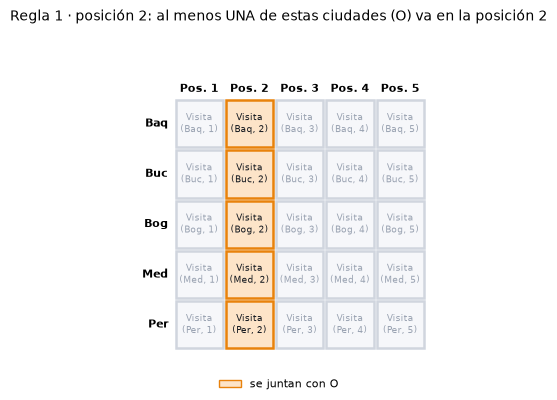

In [6]:
H.visualizar_regla(1, ejemplo=(1,))

## Regla 2: cada ciudad aparece al menos una vez

**En lenguaje natural.** Cada ciudad está en al menos una posición del recorrido.

**Como fórmula.**

$$\bigwedge_{c=0}^{n-1}\ \bigvee_{t=0}^{n-1} Visita(c,t)$$

In [7]:
mostrar_regla(2)

--- Código que genera la regla 2 ---
    def regla2(self):
        """Regla 2 — Cada ciudad está en al menos una posición.
        Y_c ( O_t Visita(c,t) )"""
        return Ytoria([Otoria([self.Visita.ravel([c, t]) for t in range(self.n)])
                       for c in range(self.n)])

--- Fórmula generada: 97 símbolos, 5 conjuntos unidos por Y ---
Conjunto 1
  Fórmula   : ((((ĀOą)OĊ)Oď)OĔ)
  En español: ((((La ciudad Baq se visita en la posicion 1 O La ciudad Baq se visita en la posicion 2) O La ciudad Baq se visita en la posicion 3) O La ciudad Baq se visita en la posicion 4) O La ciudad Baq se visita en la posicion 5)
Conjunto 2
  Fórmula   : ((((āOĆ)Oċ)OĐ)Oĕ)
  En español: ((((La ciudad Buc se visita en la posicion 1 O La ciudad Buc se visita en la posicion 2) O La ciudad Buc se visita en la posicion 3) O La ciudad Buc se visita en la posicion 4) O La ciudad Buc se visita en la posicion 5)
(... y 3 conjuntos más)


**Visualización de la regla 2.** En el conjunto de Baq se juntan con **O** sus cinco posiciones: Baq debe ir en al menos una.

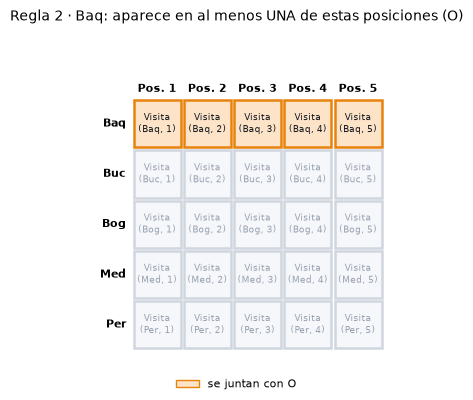

In [8]:
H.visualizar_regla(2, ejemplo=(0,))

## Regla 3: cada ciudad aparece a lo sumo una vez

**En lenguaje natural.** Cada ciudad está en a lo sumo una posición: si se visita en la posición $t$, no se visita en ninguna otra.

**Como fórmula.**

$$\bigwedge_{c=0}^{n-1}\ \bigwedge_{t=0}^{n-1}\Big( Visita(c,t)\to\neg\bigvee_{t^{\prime}\neq t} Visita(c,t^{\prime})\Big)$$

In [9]:
mostrar_regla(3)

--- Código que genera la regla 3 ---
    def regla3(self):
        """Regla 3 — Cada ciudad está en a lo sumo una posición.
        Y_c Y_t ( Visita(c,t) -> -( O_{t'!=t} Visita(c,t') ) )"""
        L = []
        for c in range(self.n):
            for t in range(self.n):
                otras = [self.Visita.ravel([c, tp]) for tp in range(self.n) if tp != t]
                L.append('(' + self.Visita.ravel([c, t]) + '>-' + Otoria(otras) + ')')
        return Ytoria(L)

--- Fórmula generada: 522 símbolos, 25 conjuntos unidos por Y ---
Conjunto 1
  Fórmula   : (Ā>-(((ąOĊ)Oď)OĔ))
  En español: (La ciudad Baq se visita en la posicion 1 >  no (((La ciudad Baq se visita en la posicion 2 O La ciudad Baq se visita en la posicion 3) O La ciudad Baq se visita en la posicion 4) O La ciudad Baq se visita en la posicion 5))
Conjunto 2
  Fórmula   : (ą>-(((ĀOĊ)Oď)OĔ))
  En español: (La ciudad Baq se visita en la posicion 2 >  no (((La ciudad Baq se visita en la posicion 1 O La ciudad Baq se visita e

**Visualización de la regla 3.** Si Bog va en la posición 2 (azul), ninguna de las otras posiciones de Bog (naranja) puede ser verdadera.

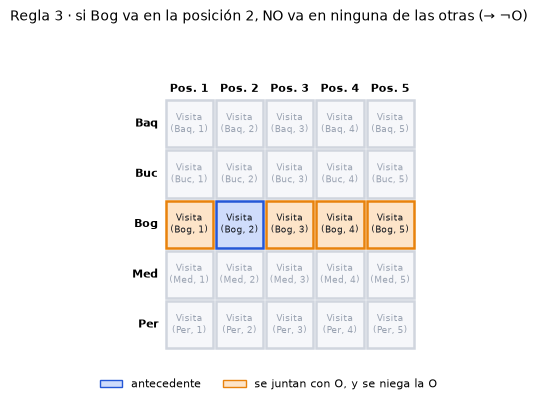

In [10]:
H.visualizar_regla(3, ejemplo=(2, 1))

## Regla 4: transiciones válidas

**En lenguaje natural.** Si en la posición $t$ se visita la ciudad $u$, en la posición $t+1$ se visita una ciudad conectada con $u$ por una carretera.

**Como fórmula.**

$$\bigwedge_{t=0}^{n-2}\ \bigwedge_{u=0}^{n-1}\Big( Visita(u,t)\to\bigvee_{v\in N(u)} Visita(v,t+1)\Big)$$

In [11]:
mostrar_regla(4)

--- Código que genera la regla 4 ---
    def regla4(self):
        """Regla 4 — Transiciones válidas (adyacencia entre posiciones consecutivas).
        Y_{t=0..n-2} Y_u ( Visita(u,t) -> O_{v vecino de u} Visita(v,t+1) )"""
        L = []
        for t in range(self.n - 1):
            for u in range(self.n):
                vec = [self.Visita.ravel([v, t + 1]) for v in range(self.n) if self.ady(u, v)]
                L.append('(' + self.Visita.ravel([u, t]) + '>' + Otoria(vec) + ')')
        return Ytoria(L)

--- Fórmula generada: 301 símbolos, 20 conjuntos unidos por Y ---
Conjunto 1
  Fórmula   : (Ā>(ĆOć))
  En español: (La ciudad Baq se visita en la posicion 1 > (La ciudad Buc se visita en la posicion 2 O La ciudad Bog se visita en la posicion 2))
Conjunto 2
  Fórmula   : (ā>((ąOć)Oĉ))
  En español: (La ciudad Buc se visita en la posicion 1 > ((La ciudad Baq se visita en la posicion 2 O La ciudad Bog se visita en la posicion 2) O La ciudad Per se visita en la posicion 2))
(... y 18

**Visualización de la regla 4.** Si Bog va en la posición 2 (azul), en la posición 3 debe ir una de sus vecinas por carretera (naranja).

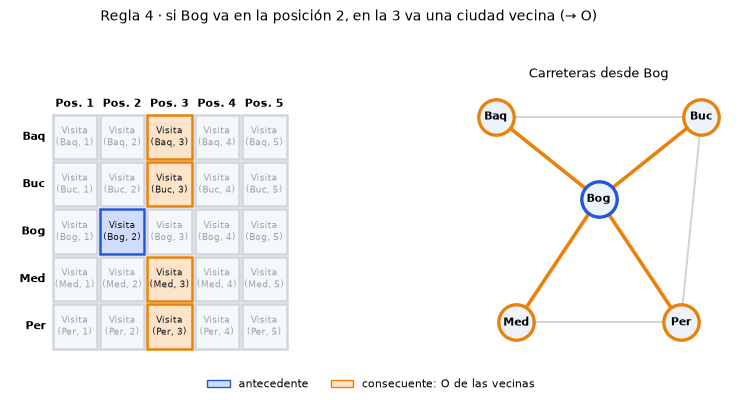

In [12]:
H.visualizar_regla(4, ejemplo=(2, 1))

## Regla 5: cierre del ciclo

**En lenguaje natural.** La ciudad de la última posición está conectada con la ciudad de la primera posición, de modo que el recorrido regresa al origen.

**Como fórmula.**

$$\bigwedge_{u=0}^{n-1}\Big( Visita(u,n-1)\to\bigvee_{v\in N(u)} Visita(v,0)\Big)$$

In [13]:
mostrar_regla(5)

--- Código que genera la regla 5 ---
    def regla5(self):
        """Regla 5 — Cierre del ciclo (la última posición conecta con la primera).
        Y_u ( Visita(u,n-1) -> O_{v vecino de u} Visita(v,0) )"""
        L = []
        for u in range(self.n):
            vec = [self.Visita.ravel([v, 0]) for v in range(self.n) if self.ady(u, v)]
            L.append('(' + self.Visita.ravel([u, self.n - 1]) + '>' + Otoria(vec) + ')')
        return Ytoria(L)

--- Fórmula generada: 73 símbolos, 5 conjuntos unidos por Y ---
Conjunto 1
  Fórmula   : (Ĕ>(āOĂ))
  En español: (La ciudad Baq se visita en la posicion 5 > (La ciudad Buc se visita en la posicion 1 O La ciudad Bog se visita en la posicion 1))
Conjunto 2
  Fórmula   : (ĕ>((ĀOĂ)OĄ))
  En español: (La ciudad Buc se visita en la posicion 5 > ((La ciudad Baq se visita en la posicion 1 O La ciudad Bog se visita en la posicion 1) O La ciudad Per se visita en la posicion 1))
(... y 3 conjuntos más)


**Visualización de la regla 5.** Si Bog va en la última posición (azul), en la primera debe ir una de sus vecinas por carretera (naranja).

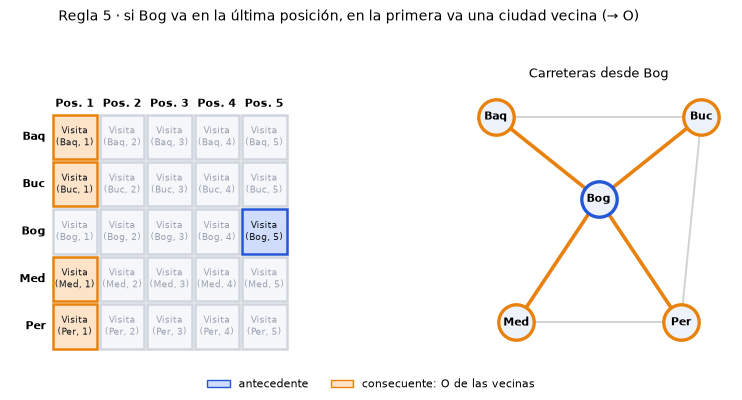

In [14]:
H.visualizar_regla(5, ejemplo=(2,))

## Comprobación de las reglas con modelos construidos a mano

Para confirmar que las fórmulas dicen lo que dice el lenguaje natural, evaluamos las 5 reglas sobre recorridos que armamos nosotros: uno válido y otros que rompen reglas a propósito. `modelo_de(orden)` construye la interpretación con las 25 letras: `orden[t]` es la ciudad de la posición `t` (`None` si esa posición queda vacía).

In [15]:
def modelo_de(orden):
    I = {}
    for c in range(H.n):
        for t in range(H.n):
            I[H.Visita.ravel([c, t])] = (orden[t] == c)
    return I

reglas_arbol = [inorder_to_tree(f) for f in H.reglas]

casos = [('Ciclo válido', [0, 1, 4, 3, 2], []),
         ('No cierra el ciclo (Per no conecta con Baq)', [0, 1, 2, 3, 4], [5]),
         ('Salto sin carretera (Baq -> Med)', [0, 3, 1, 2, 4], [4]),
         ('Ciudad repetida y otra ausente', [0, 1, 4, 3, 0], [2, 3]),
         ('Posición sin ciudad', [0, 1, None, 3, 2], [1])]

filas, todo_ok = [], True
for nombre, orden, deben_fallar in casos:
    I = modelo_de(orden)
    res = [A.valor(I) for A in reglas_arbol]
    ok = all(not res[k - 1] for k in deben_fallar) and (res == [True] * 5 if not deben_fallar else True)
    todo_ok = todo_ok and ok
    fila = {'Recorrido': nombre}
    fila.update({f'Regla {k}': res[k - 1] for k in range(1, 6)})
    fila['Debe fallar'] = ', '.join(map(str, deben_fallar)) or '-'
    filas.append(fila)

print('¿Las reglas que deben fallar fallan, y el ciclo válido las cumple todas?', todo_ok)
pd.DataFrame(filas)

¿Las reglas que deben fallar fallan, y el ciclo válido las cumple todas? True


,Recorrido,Regla 1,Regla 2,Regla 3,Regla 4,Regla 5,Debe fallar
0,Ciclo válido,True,True,True,True,True,-
1,No cierra el ciclo (Per no conecta con Baq),True,True,True,True,False,5
2,Salto sin carretera (Baq -> Med),True,True,True,False,False,4
3,Ciudad repetida y otra ausente,True,False,False,False,False,"2, 3"
4,Posición sin ciudad,False,False,True,False,True,1


## Un recorrido completo, turno por turno

Hasta aquí vimos las reglas por separado. Ahora le damos a las reglas un **modelo armado a mano** (un recorrido completo), comprobamos que las cumple y lo dibujamos **turno por turno** con `H.visualizar_por_turnos`. Más adelante, un **SAT-solver** encontrará la solución por sí solo.

## Un modelo a mano

Un **modelo** es un recorrido concreto (qué ciudad va en cada turno), escrito como un diccionario
`Visita(c,t) → True/False`. Lo escribimos **a mano** eligiendo un recorrido válido.

<div style="background:#e8f5ec; border-left:5px solid #16915a; padding:12px 16px; border-radius:8px;">
💡 <b>Nota:</b> el modelo lo damos a mano solo para <b>probar</b> que las reglas y el visualizador
funcionan. Mas adelante, un <b>SAT solver</b> encontrará la solución <b>por sí solo</b>.
</div>

In [16]:
# El modelo a mano (Paso 1)
recorrido = ['Baq','Buc','Per','Med','Bog']
I_mano = {}
for t, nombre in enumerate(recorrido):
    c_turno = ciudades.index(nombre)
    for c in range(5):
        I_mano[H.Visita.ravel([c,t])] = (c == c_turno)

## Verificación numérica

Comprobamos que el modelo cumple **todas** las reglas: <code>conj.valor(I_mano)</code> debe dar
<b>True</b>. También evaluamos **regla por regla** para confirmar que cada una acepta un recorrido
válido (y que con uno inválido, la regla correspondiente lo rechaza con <b>False</b>).

In [17]:
# Las 5 reglas juntas en una sola fórmula
conj = inorder_to_tree(Ytoria(H.reglas))

# ¿Cumple TODAS las reglas?
print("Conjunción de las 5 reglas:", conj.valor(I_mano))   # True

# Regla por regla
for i, r in enumerate(H.reglas, 1):
    print(f"Regla {i}:", inorder_to_tree(r).valor(I_mano))

Conjunción de las 5 reglas: True
Regla 1: True
Regla 2: True
Regla 3: True
Regla 4: True
Regla 5: True


## Comprobación visual de las reglas

Además de los números, comprobamos que las reglas están bien planteadas **mirando el dibujo**.
Las carreteras usadas van en <span style="color:#2457d6;"><b>azul</b></span> y el cierre del ciclo en
<span style="color:#e8820c;"><b>naranja</b></span>. Cada regla tiene su "firma visual":

| Regla | Qué se MIRA en el dibujo para confirmarla |
|---|---|
| **1 y 2** (una ciudad por turno / cada ciudad se visita) | Que en los **5 turnos** aparezcan las **5 ciudades**, cada una **exactamente una vez** |
| **3** (a lo sumo una posición por ciudad) | Que **ninguna ciudad** aparezca en **dos turnos** distintos |
| **4** (adyacencia) | Que cada <span style="color:#2457d6;"><b>flecha azul</b></span> caiga encima de una **línea gris** (carretera real) |
| **5** (cierre del ciclo) | Que la <span style="color:#e8820c;"><b>flecha naranja</b></span> conecte la última ciudad con la primera, sobre una carretera |

Si el dibujo cumple todo lo anterior, las reglas están **bien planteadas** — lo confirmamos a simple vista. ✅

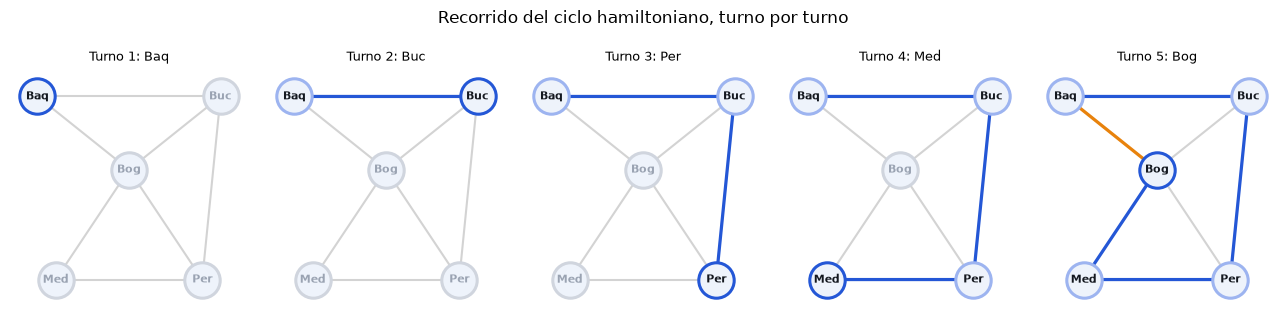

In [18]:
H.visualizar_por_turnos(I_mano) 

## Conclusión

<div style="background:#eef3fb; border-left:5px solid #2457d6; padding:12px 16px; border-radius:8px;">
<ul style="margin:0;">
<li>Implementamos el problema con un <b>único descriptor</b> <code>Visita(c,t)</code> (25 letras).</li>
<li><b>Verificamos</b> que las reglas aceptan un recorrido válido y rechazan uno inválido.</li>
<li><b>Visualizamos</b> la solución <b>turno por turno</b>, confirmando a simple vista que es un ciclo hamiltoniano válido.</li>
</ul>
</div>

En los notebooks `02` a `05`, un **SAT-solver** encuentra la solución automáticamente a partir de estas mismas reglas.

## Guardar las reglas (opcional)

Guardamos las 5 reglas generadas en `datos/reglas.json` (cada regla es la cadena de la fórmula, en notación inorder). Es un archivo **opcional**: sirve para cargar las reglas sin volver a generarlas.

In [19]:
import os, json

os.makedirs('datos', exist_ok=True)
reglas = {f'Regla {k}': H.reglas[k - 1] for k in range(1, 6)}
with open('datos/reglas.json', 'w') as f:
    json.dump(reglas, f)

with open('datos/reglas.json') as f:
    leidas = json.load(f)
print('Guardado datos/reglas.json | ¿se lee igual?', leidas == reglas)
for nombre, formula in leidas.items():
    print(f'  {nombre}: {len(formula)} símbolos')

Guardado datos/reglas.json | ¿se lee igual? True
  Regla 1: 97 símbolos
  Regla 2: 97 símbolos
  Regla 3: 522 símbolos
  Regla 4: 301 símbolos
  Regla 5: 73 símbolos
